# Механизм IOI

Добрый день. Сегодня мы рассматриваем статью "Indirect Object Identification (IOI)" или идентификация косвенного объекта. В указанной статье так же цитируется очень много материала из статьи [Interpretability in the Wild: a Circuit for Indirect Object Identification in GPT-2 small](https://arxiv.org/html/2211.00593v1#S2).

Сначала опишем ключевые понятия, используемые в статьях.

IOI -- это бенчмарк прогнозирования следующего токена, при котором измеряется способность языковой модели правильно выбирать косвенное лицо (в сторону которого совершается действие) вместо действующего лица.

В рамках бенчмарка IOI используются следующие обозначения: S -- subject (подлежащие), S1 -- первое упоминание действующего лица, S2 -- второе упоминание действующего лица, IO -- косвенный объект, косвенное дополнение, END -- конец предложение куда необходимо подставить предсказание.

На вход нейронной сети подайтся неполное предложение, являющееся составным. В придаточной части предложения в подлежащее входят два имени (озвучивается два действующих лица), однако во второй части до пропускания предложения через модель в качестве действующего лица присутствует только одно имя. Indirect object -- это имя, которое не повторилось и должно быть дописано нейронной сетью в предложении. Indirect object является не сколько правилом грамматики языка (с точки зрения языка на место Indirect object можно поставить сколько угодно других слов), сколько правилом набора. Из этого вытекает удобство использования IOI в качестве бенчмарка: ответ заранее известен, а имена, порядок предложения и т.п. можно менять, сохраняя логический посыл и структуру.

Рассмотрим пример предложения, используемого в IOI:
> **"When Mary and John went to the store John gave a book to"**


In [ ]:
import os
from pathlib import Path
import sys, time, json
from importlib.metadata import version

OFFLINE = True
os.environ["HF_HUB_OFFLINE"] = "1" if OFFLINE else "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
import ioi
import circuit_experiments as circuit
import path_patching as paths
import signal_experiments as signals
import english_figures as figures

OUTPUT = Path("IOI_research_results")
OUTPUT.mkdir(exist_ok=True)
started = time.perf_counter()
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "font.family": "DejaVu Sans"})

def save_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def save_table(frame, name):
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
    display(frame.round(3))


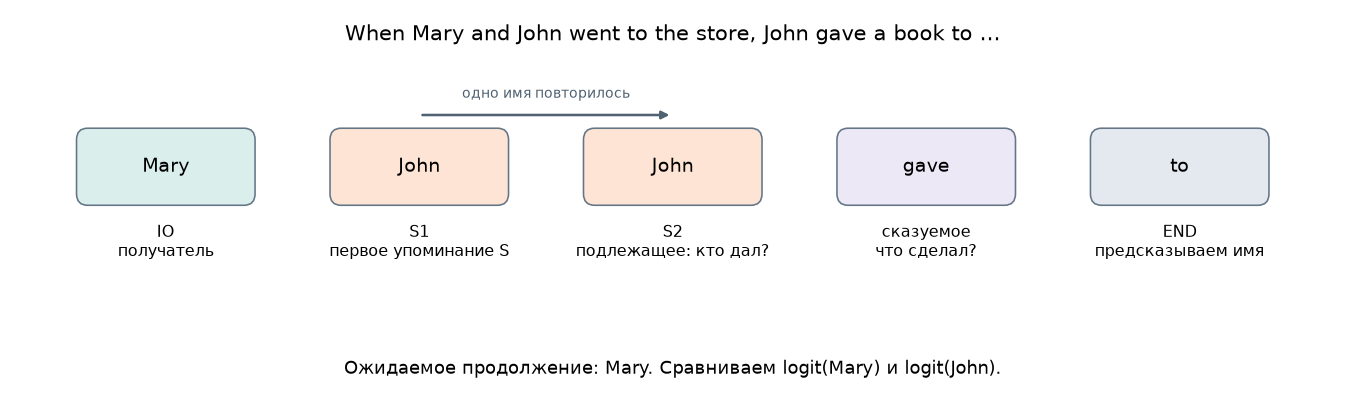

In [ ]:
save_figure(figures.sentence_roles(), "00a_sentence_roles")



Слово **Mary** является indirect object, т.е. именем, которое неповторилось.

Измерение качества способности подставлять нужное слово в качестве косвенного дополнения происходит следующим образом:

1. Модели даётся на вход незаконченное предложение, обрывающееся на месте где должен находится косвенный объект, напр.:

    > *When Mary and John went to the store, John gave a book to*

2. Модель предсказывает следующий токен.

3. Мы берём логиты действующего и косвенного объектов, получившиеся из матрицы анэмбеддинга (до того как они пройдут через нормализацию softmax).

4. Вычитаем логит действующего объекта из логита косвенного объекта:
$$D=\mathrm{logit}(IO)-\mathrm{logit}(S)$$

До нормализации логиты представляют из себя вещественные числа, варьирующиеся от $-\infty$ до $+\infty$, поэтому сумма $D$ будет так же варьироваться от $-\infty$ до $+\infty$. В зависимости от значения $D$ можно сделать следующие выводы:

- $D > 0$ -- Модель предпочитает IO.
- $D = 0$ -- Модели всё равно какое слово выбрать.
- $D < 0$ -- Модель выбирает S.


В данном исследовании воспроизводится механизм IOI в GPT-2 Small.

# Механизм IOI в GPT 2 Small

В статье "Interpretability in the Wild" промпты для IOI создаются с использованием 15 подготовленных шаблонов, 100 английских имён состоящих из одного токена, 20 мест действия и 20 предметов, над которыми совершаются действия.

В статье приводится следующая статистика:
- В 99,3% случаев indirect object имел более высокий логит, чем подлежащее.
- Средняя вероятность indirect object по всему словарю составила 49% (неинтуитивно, но оставшиеся 51% разделяли между собой все остальные токены из словаря анэмбединг матрицы)
- На 100000 примерах среднее значение $D$ составило 3,56.

Большое значение $D$ на конкретном примере говорит много о чём, особенно если сравнивать результаты бенчмарка со значениями других примеров. Высокое значение $D$ относительно других примеров показывает более высокую степень предпочтительности правильного имени в конкретном случае. Однако в рамках дисциплины Механическая интерпретация нас интересует не какой ответ выбирает модель, а как именно. Чтобы разобраться в механизме, необходимо проверить, какие внутринние вычисления влияют на ответ модели.

Предположим, что некоторая голова внимания смотрит на токен **Mary** -- это не означает, что она помогает модели выбрать это слово так как её активность может только сопровождать выбор, обеспечивающий другими компонентами. Для проверки мы вмешиваемся в вычисление и измеряем изменение результата -- значения числа $D$.

Существует несколько подходов внесения изменений в работу нейронной сети для исследовательских целей:

- Зануление выходных данных головы внимания (*англ.* Zero Ablation).
- Mean ablation -- замена выходных данных головы внимания усреднённым значениями по набору примеров, т.е. вместо конкретных сигналов подставляется общий фон. В статье Interpretability in the Wild авторы используют эту абляцию.
- Подстановка активаций (*англ.* activation patching) -- замена выхода выбранной головы внимания значением, полученным от той же головы при обработке другого предложения.
- Подстановка на выбранных путях (*англ.* path patching) -- Замена сигнала выбранной головы внимания значением из другого прогона только на определённых путях к выбраным компонентам.

## 2. Архитектура и circuit

GPT-2 Small содержит **12 слоёв по 12 голов внимания, всего 144 головы**. L9H6 — голова 6 в слое 9; нумерация начинается с нуля. Голова — вычислительный модуль, а не отдельный нейрон. Внимание переносит информацию между позициями; MLP преобразует представление каждой позиции отдельно.

[Attention Is All You Need](https://arxiv.org/abs/1706.03762) описывает encoder–decoder. GPT-2 использует только причинное самовнимание: токен читает себя и предыдущий текст. Представления хранятся в **residual stream** — общем состоянии, к которому головы и MLP прибавляют результаты. **Активации** — эти промежуточные векторы; они меняются с текстом, хотя веса модели фиксированы.


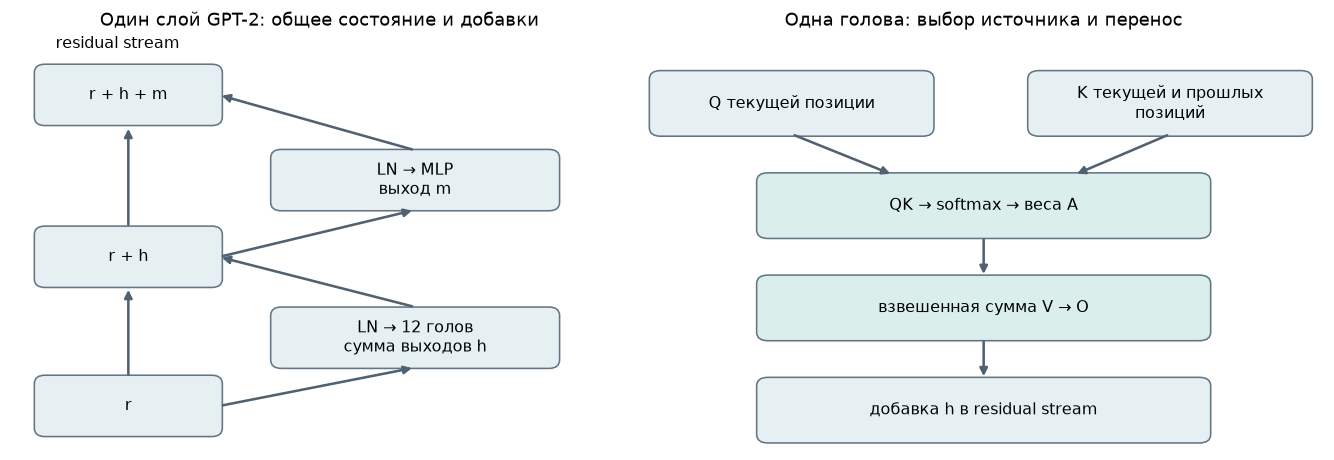

In [ ]:
save_figure(figures.transformer_block(), "00b_transformer_block")


Для одной головы, опуская смещения:

$$q_i=u_iW_Q,\quad k_j=u_jW_K,\quad v_j=u_jW_V,$$
$$A_{ij}=\operatorname{softmax}_{j\leq i}\left(\frac{q_i k_j^\top}{\sqrt{d_k}}\right),\qquad h_i=\left(\sum_{j\leq i}A_{ij}v_j\right)W_O.$$

$i$ — читающая позиция, $j$ — источник, $d_k=64$. Query $q$ задаёт запрос, key $k$ участвует в выборе источника, value $v$ несёт содержимое. **QK определяет, откуда читать; OV — что записать.** $u$ — представление после LayerNorm (LN), нормализующей его среднее и масштаб. [Elhage et al.](https://transformer-circuits.pub/2021/framework/)

После последнего слоя LN и линейное **unembedding** переводят состояние END в логиты следующего токена. В коде `z` обозначает сумму $\sum_j A_{ij}v_j$ до матрицы O; логиты обозначаем словом `logit`, чтобы не путать две величины.


### Предложенный механизм

**Circuit** — часть вычислительного графа, объясняющая конкретное поведение. Узлами могут быть головы, нейроны или признаки. Они не образуют новый физический блок: исследователь выделяет связанную цепочку внутри обученной сети.

Для IOI авторы нашли **26 голов семи групп на определённых позициях**. Duplicate обнаруживают повтор; Previous Token и Induction используют структуру `A B … A`, связывая повтор A с позицией следующего B. S-Inhibition передаёт информацию о повторённом имени, чтобы Name Movers избегали S1. Name Movers читают IO и повышают его логит. [Wang et al., §3](https://arxiv.org/html/2211.00593v1#S3)

`S1+1` — токен сразу после первого упоминания отправителя.


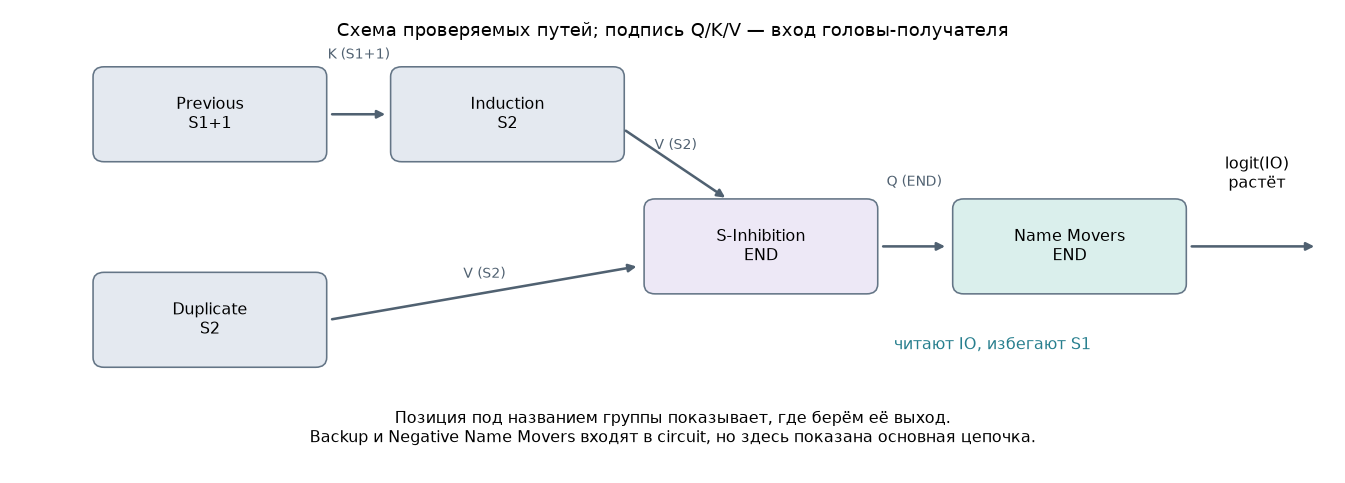

In [ ]:
save_figure(figures.circuit_route(), "00c_circuit_route")


## 3. Данные и исходное качество

Используем GPT-2 Small на CPU без обновления весов. Для каждого из двух шаблонов берём 16 однотокенных имён: 8 пар, оба порядка первого упоминания и оба отправителя. Получаем 32 примера на шаблон, всего 64; правило «выбрать первое имя» даёт 50%. Позиции проверяем после токенизации, seed фиксирован.

Второй шаблон сохраняет имена и меняет формулировку. Для дорогих вмешательств берём первые 4 полные пары основного шаблона, то есть 16 примеров. ABC-примеры содержат три разных имени и не имеют повтора, определяющего ответ IOI.

Версии и результаты выводятся кодом; графики и таблицы сохраняются в `IOI_research_results`. Вычислительные функции и оформление графиков вынесены в Python-файлы рядом с ноутбуком. Для первого скачивания весов на другом компьютере установите `OFFLINE = False`.

In [ ]:
model = ioi.load_model(device="cpu")
environment = {p: version(p) for p in
               ["torch", "transformers", "transformer-lens", "numpy", "pandas", "matplotlib"]}
print("Python:", sys.executable)
print("Модель:", ioi.MODEL, "revision:", ioi.REVISION)
print("CPU; слоёв:", model.cfg.n_layers, "голов на слой:", model.cfg.n_heads)
print(environment)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Python: /home/nikolay/miniconda3/bin/python
Модель: openai-community/gpt2 revision: 607a30d783dfa663caf39e06633721c8d4cfcd7e
CPU; слоёв: 12 голов на слой: 12
{'torch': '2.10.0', 'transformers': '5.17.0', 'transformer-lens': '4.0.0', 'numpy': '2.5.2', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


In [ ]:
# Все головы заданы по статье до просмотра наших результатов.
family_rows = []
for family, (heads, position) in circuit.CIRCUIT.items():
    family_rows.append({"Группа": family, "Головы (слой.голова)": ", ".join(f"{l}.{h}" for l, h in heads),
                        "Позиция": {"end": "END", "s2_pos": "S2", "s1_next": "S1+1"}[position]})
save_table(pd.DataFrame(family_rows), "circuit_nodes")


,Группа,Головы (слой.голова),Позиция
0,Previous Token,"2.2, 4.11",S1+1
1,Duplicate Token,"0.1, 3.0, 0.10",S2
2,Induction,"5.5, 6.9, 5.8, 5.9",S2
3,S-Inhibition,"7.3, 7.9, 8.6, 8.10",END
4,Name Mover,"9.6, 9.9, 10.0",END
5,Negative Name Mover,"10.7, 11.10",END
6,Backup Name Mover,"9.0, 9.7, 10.1, 10.2, 10.6, 10.10, 11.2, 11.9",END


In [ ]:
full_data = {name: ioi.prepare(model, ioi.make_examples(name)) for name in ioi.TEMPLATES}
full_scores = {name: ioi.forward_scores(model, data) for name, data in full_data.items()}
baseline_rows, example_rows = [], []
for name, data in full_data.items():
    score = full_scores[name]
    baseline_rows.append({"Шаблон": name, "N": len(data["examples"]),
                          "Среднее D": float(score["D"].mean()),
                          "Доля D > 0": float((score["D"] > 0).float().mean()),
                          "IO — top-1": float(score["top1_is_io"].float().mean()),
                          "Среднее p(IO)": float(score["p_io"].mean())})
    for i, row in enumerate(data["examples"]):
        example_rows.append({**row, "D": float(score["D"][i]), "p_io": float(score["p_io"][i])})
    print(name + ":", data["examples"][0]["prompt"])
save_table(pd.DataFrame(baseline_rows), "baseline")
pd.DataFrame(example_rows).to_csv(OUTPUT / "examples.csv", index=False)

small = ioi.prepare(model, ioi.make_examples("main")[:16])
clean = ioi.forward_scores(model, small)
corrupt = ioi.forward_scores(model, small, kind="corrupt")
print("Для вмешательств: N =", len(small["examples"]), "clean D =", round(float(clean["D"].mean()), 3))


main: When Sarah and Daniel went to the store, Sarah gave a book to
heldout: After Sarah and Daniel entered the office, Sarah handed a letter to


,Шаблон,N,Среднее D,Доля D > 0,IO — top-1,Среднее p(IO)
0,main,32,4.265,1.0,1.0,0.561
1,heldout,32,3.359,1.0,1.0,0.566


Для вмешательств: N = 16 clean D = 4.475


Исходное качество подтверждает, что модель решает задачу на наших шаблонах. Высокая точность на 64 связанных примерах сама по себе не устанавливает механизм.

### Что читают Name Movers и что делают с именем?

На матрице внимания строка — читающая позиция, столбец — источник. Веса строки суммируются в единицу, будущие позиции закрыты причинной маской. BOS — служебный токен начала последовательности. Строка END показывает, откуда голова получает информацию перед ответом. Сначала смотрим один пример, затем усредняем веса на IO, S1 и S2 по 16 фразам.


In [ ]:
# Матрица одной головы и средние веса на позициях с разными ролями.
selected_attention = [(9, 6), (9, 9), (10, 0), (8, 10), (10, 7)]
patterns = {layer: ioi.attention(model, small["clean"], layer)
            for layer in sorted({l for l, h in selected_attention})}
labels = ["BOS"] + [model.tokenizer.decode([int(t)]) for t in small["clean"][0, 1:]]
rows = torch.arange(len(small["examples"]))
attention_rows = []
for layer, head in selected_attention:
    a = patterns[layer][:, head, -1]
    assert torch.allclose(a.sum(-1), torch.ones(len(a)), atol=1e-5)
    attention_rows.append({"Голова": f"L{layer}H{head}", **{
        role: float(a[rows, small[pos]].mean())
        for role, pos in [("IO", "io_pos"), ("S1", "s1_pos"), ("S2", "s2_pos")]}})
attention_df = pd.DataFrame(attention_rows)
attention_df.to_csv(OUTPUT / "attention.csv", index=False)


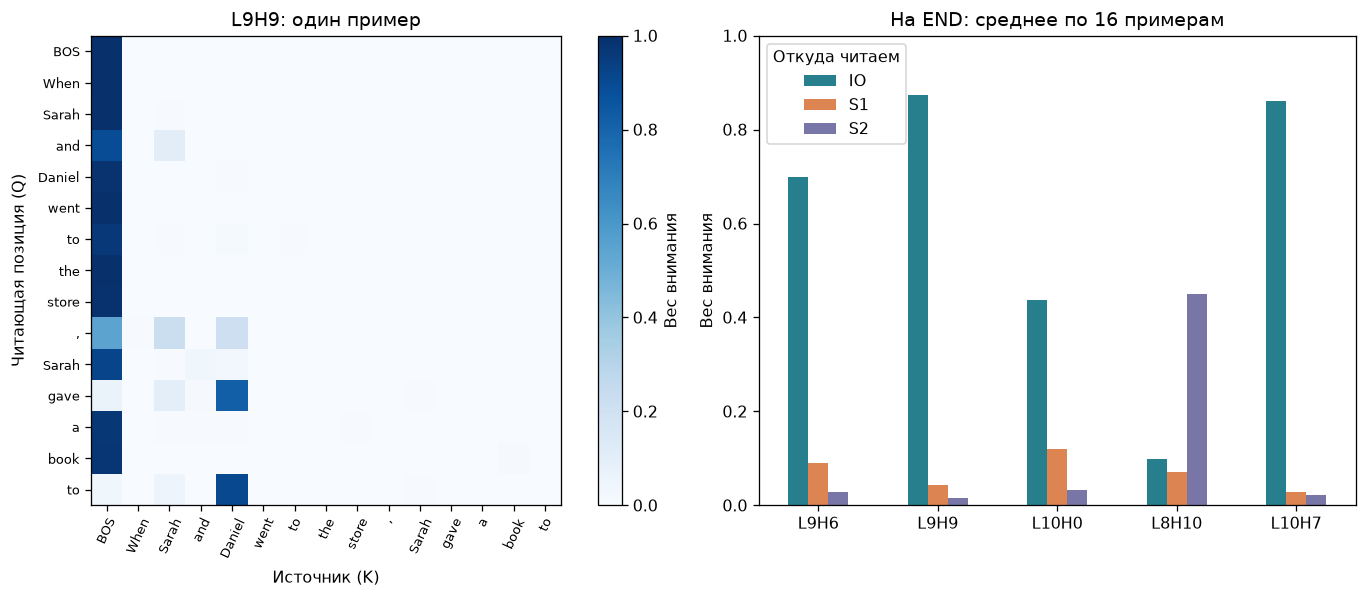

Пример: When Sarah and Daniel went to the store, Sarah gave a book to


In [ ]:
save_figure(figures.attention(patterns, small, model, attention_df), "01_attention")
print("Пример:", small["examples"][0]["prompt"])


Последний входной токен `to` — END; ответ ещё не добавлен. Name Movers читают IO, а S-Inhibition L8H10 — S2. В правой панели показаны только три позиции, поэтому сумма столбиков может быть меньше единицы. Высокий вес сам по себе ещё не доказывает влияние на ответ.


**Copy score** проверяет следующую часть механизма: если голова полностью прочитает имя, поднимет ли её преобразование OV это имя в top-5 выходных оценок? У авторов все три Name Movers получили более 95%. [Wang et al., §3.1](https://arxiv.org/html/2211.00593v1#S3.SS1)

Берём состояние имени после MLP первого слоя, применяем LN, V, O, финальную LN и unembedding. Остальной residual stream не добавляем. Для Negative Heads также проверяем отрицание выхода OV. Это адаптированная диагностика [check_copy_circuit](https://github.com/redwoodresearch/Easy-Transformer/blob/main/experiments.py) в параметризации **TransformerLens**, а не точность полной модели и не точная копия авторского кода.


,head_label,group,copy_score,negative_copy_score,n_contexts
0,L9H6,Name Mover,0.771,0.0,96
1,L9H9,Name Mover,1.000,0.0,96
2,L10H0,Name Mover,0.875,0.0,96
3,L10H7,Negative Name Mover,0.000,1.0,96
4,L11H10,Negative Name Mover,0.000,1.0,96
5,L9H1,Comparison,0.000,0.0,96
6,L9H2,Comparison,0.125,0.0,96
7,L10H3,Comparison,0.000,0.0,96


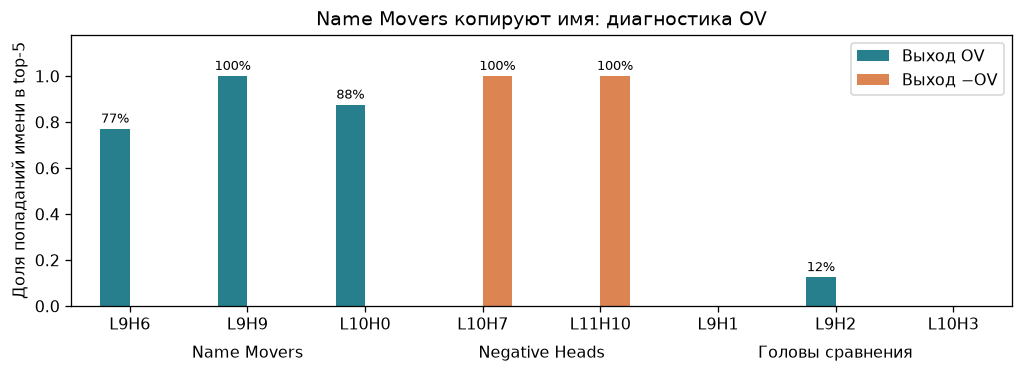

In [ ]:
copy_df = pd.DataFrame(circuit.copy_scores(model, full_data["main"]))
copy_df["head_label"] = [f"L{l}H{h}" for l, h in zip(copy_df.layer, copy_df["head"])]
save_table(copy_df[["head_label", "group", "copy_score", "negative_copy_score", "n_contexts"]], "copy_scores")
save_figure(figures.copying(copy_df), "01b_copy_score")


На 96 вхождениях имён основные Name Movers получили 77.1%, 100.0% и 87.5%. Копирование выражено, но порог статьи «более 95% для каждой головы» здесь полностью не повторился. Выборка и реализация диагностики различаются; по одному этому числу причину расхождения не определить.


## 4. Абляции и activation patching

Внимание показывает, куда смотрит голова. Для проверки её влияния меняем внутреннее вычисление и измеряем ответ. Во всех вмешательствах веса модели остаются прежними.


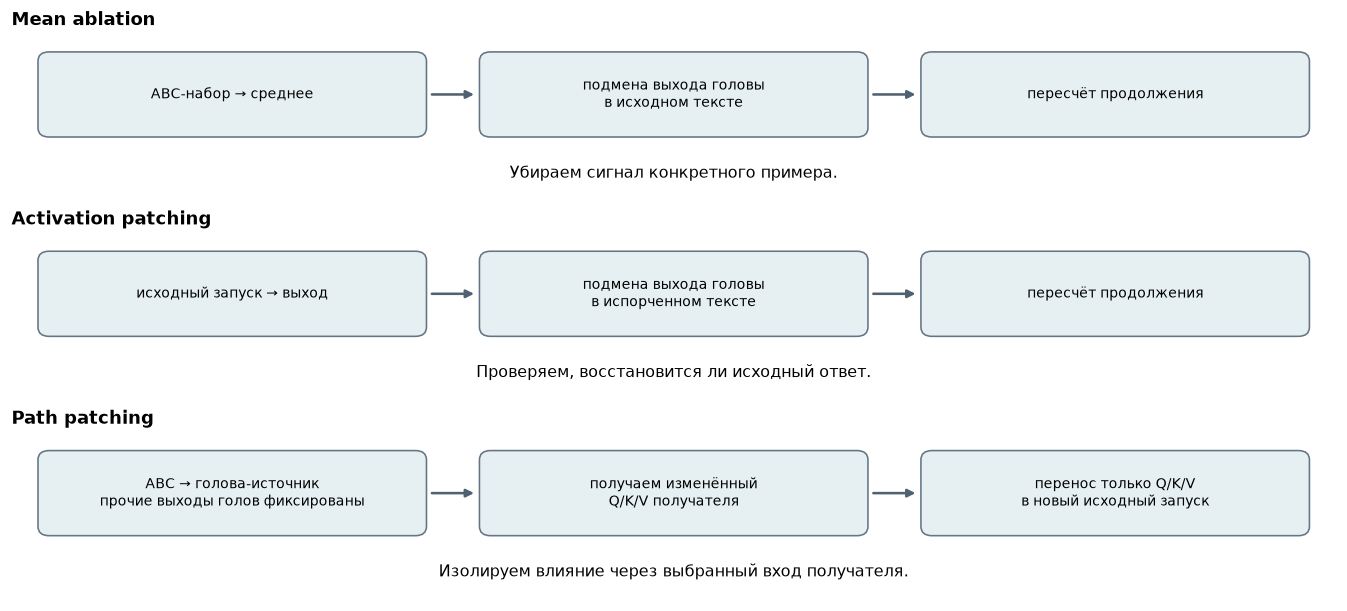

In [ ]:
save_figure(figures.intervention_scheme(), "01c_interventions")


### 4.1. Что сохраняется после выделения circuit

**Абляция** заменяет активацию компонента, чтобы измерить его влияние на ответ. При **zero ablation** подставляем ноль; при **mean ablation** — среднее по другим примерам. Среднее сохраняет фоновый выход, но убирает сигнал конкретного примера. Веса модели остаются прежними. Входной текст остаётся исходным: меняется только внутреннее вычисление.

Референсный набор — 32 ABC-фразы с тремя разными именами, например `When Mary and John went to the store, Alice gave a book to`. Каждое имя одинаково часто занимает каждую роль. Средние считаем отдельно для каждого шаблона, слоя, головы и позиции.

Оставляем 26 узлов circuit из таблицы: **голову на конкретной позиции**. Остальные выходы голов на всех позициях подменяем ABC-средними. Эмбеддинги, MLP и нормализации продолжают работать.

$$R=\frac{\overline D_{circuit}}{\overline D_{full}}.$$

Это сохранённая доля средней разницы логитов, а не точность или доля нейронов. У авторов она составляла около 87%; наше значение измеряем независимо. [Wang et al., §4](https://arxiv.org/html/2211.00593v1#S4)

Два контроля: сохранение всех узлов должно вернуть исходный результат; замена всех узлов средними задаёт точку сравнения.


In [ ]:
means, circuit_runs, retention_rows = {}, {}, []
for name, data in full_data.items():
    means[name] = circuit.mean_z(model, name)
    run = circuit.evaluate_circuit(model, data, means[name])
    circuit_runs[name] = run
    retention_rows.append({"Шаблон": name, "Полная модель": float(run["baseline"]["D"].mean()),
                           "26 узлов": float(run["circuit"]["D"].mean()),
                           "Все головы заменены средними": float(run["allmean"]["D"].mean()),
                           "Сохранение R": run["retention"],
                           "Ошибка identity": run["max_identity_error"]})
    pd.DataFrame({"full_D": run["baseline"]["D"].numpy(),
                  "circuit_D": run["circuit"]["D"].numpy(),
                  "allmean_D": run["allmean"]["D"].numpy()}).to_csv(OUTPUT / f"circuit_{name}.csv", index=False)
retention_df = pd.DataFrame(retention_rows)
save_table(retention_df, "retention")


,Шаблон,Полная модель,26 узлов,Все головы заменены средними,Сохранение R,Ошибка identity
0,main,4.265,3.628,0.0,0.851,0.0
1,heldout,3.359,2.831,0.0,0.843,0.0


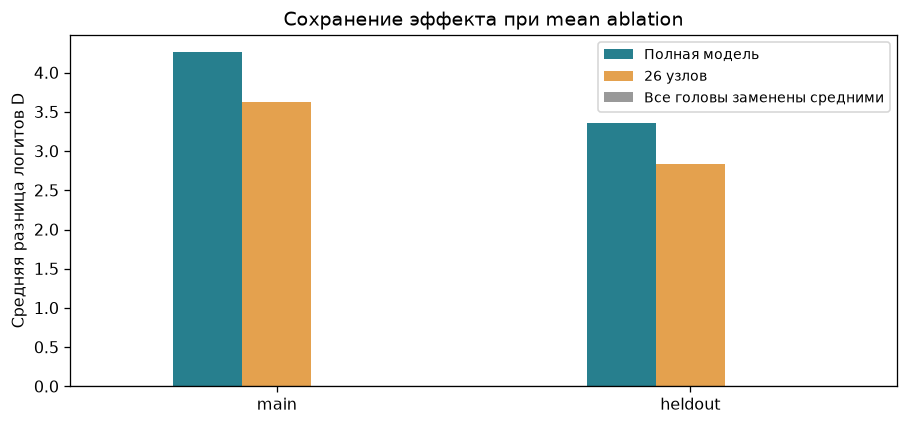

In [ ]:
save_figure(figures.retention(retention_df), "02_circuit_retention")


После выделения circuit сохраняется 85.1% среднего D на основном шаблоне и 84.3% на втором. При замене всех голов средними средний D равен нулю: на сбалансированном наборе роли имён взаимно компенсируются. Однако среднее может скрывать отдельные ошибки.


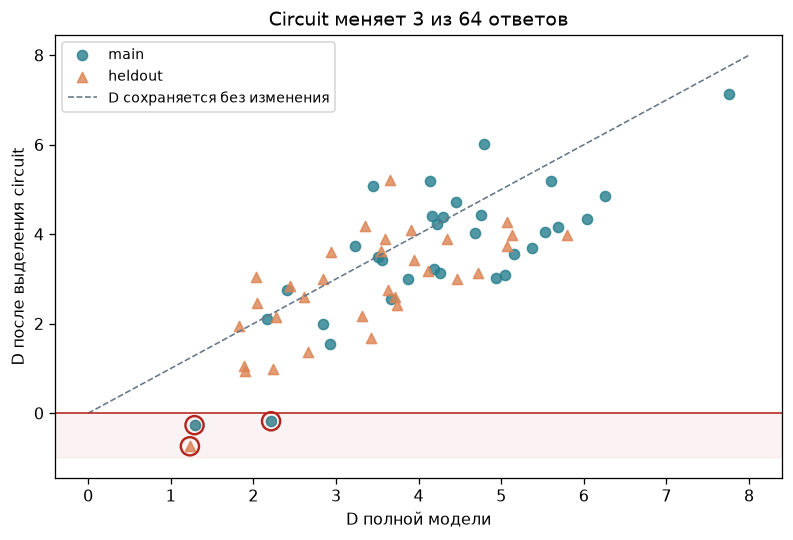

,Шаблон,Текст,IO,Полная модель D,Circuit D
0,main,"When David and Michael went to the store, Mich...",David,1.289,-0.267
1,main,"When Tom and James went to the store, James ga...",Tom,2.215,-0.179
2,heldout,"After Tom and James entered the office, James ...",Tom,1.233,-0.739


In [ ]:
save_figure(figures.circuit_scatter(circuit_runs), "02b_circuit_examples")
failures = []
for name, run in circuit_runs.items():
    for i, example in enumerate(full_data[name]["examples"]):
        if run["baseline"]["D"][i] > 0 and run["circuit"]["D"][i] <= 0:
            failures.append({"Шаблон": name, "Текст": example["prompt"], "IO": example["io_name"],
                             "Полная модель D": float(run["baseline"]["D"][i]),
                             "Circuit D": float(run["circuit"]["D"][i])})
save_table(pd.DataFrame(failures), "circuit_failures")


Красные окружности отмечают три изменения ответа: полная модель решает 32/32 примера на каждом шаблоне, circuit — 30/32 и 31/32. Например, для `David and Michael … Michael gave …` D падает с 1.29 до −0.27. Circuit сохраняет большую часть среднего эффекта, но не все решения.


### 4.2. Абляция отдельных компонентов

Теперь оставляем всю модель и подменяем только выбранную голову или группу на END. Такая проверка отвечает на другой вопрос: **что произойдёт, если сигнал этой группы станет недоступен остальной сети?**

$$\Delta D_{ablation}=\overline D_{clean}-\overline D_{ablated}.$$

Красный цвет означает потерю предпочтения IO. Синий означает, что после вмешательства предпочтение IO выросло: удалённый компонент мог давать отрицательный вклад. После подмены последующие головы и MLP пересчитываются.

### 4.3. Восстановление ответа через activation patching

Создаём парный испорченный вход, изменив только S2: `Mary and John ... John gave ...` превращается в `Mary and John ... Mary gave ...`. Правильный получатель меняется. Метрику продолжаем считать относительно исходных IO и S, поэтому D испорченного входа обычно отрицательно.

**Activation patching** переносит внутреннее состояние из одного запуска в другой. Сохраняем выход выбранной головы на END из исходного текста и вставляем его в испорченный запуск. Токены остаются испорченными; все последующие вычисления пересчитываются. Если ответ возвращается к исходному IO, перенесённый сигнал причинно влияет на выбор.

$$R_{patch}=\frac{\overline D_{patched}-\overline D_{corrupt}}{\overline D_{clean}-\overline D_{corrupt}}.$$

Здесь 0 означает отсутствие восстановления, 1 — возврат к среднему исходному D. Значение может быть меньше 0 или больше 1: это не вероятность. На рисунке показываем также ненормированный прирост D, чтобы не смешивать разные шкалы.


In [ ]:
groups = {"Name Movers": ioi.NAME_MOVERS, "S-Inhibition": ioi.S_INHIBITION,
          "Negative": ioi.NEGATIVE, "Сравнение": ioi.CONTROL}
selected_heads = sorted(set(head for heads in groups.values() for head in heads))
clean_z = ioi.cache_end_z(model, small["clean"], [l for l, h in selected_heads])
mean_end = {l: z[-1] for l, z in means["main"].items()}
zeros = {l: torch.zeros_like(z) for l, z in mean_end.items()}
d_clean, d_corrupt = float(clean["D"].mean()), float(corrupt["D"].mean())
assert abs(d_clean - d_corrupt) > 1e-5


In [ ]:
intervention_rows = []
cases = [(f"L{l}H{h}", [(l, h)], l, h) for l, h in selected_heads]
cases += [(label, heads, None, None) for label, heads in groups.items()]
for label, heads, layer, head in cases:
    ablated = ioi.intervene(model, small, heads, mean_end, kind="clean")
    patched = ioi.intervene(model, small, heads, clean_z, kind="corrupt")
    row = {"Компонент": label, "layer": layer, "head": head,
           "mean_ablation_drop": d_clean - float(ablated["D"].mean()),
           "patch_gain": float(patched["D"].mean()) - d_corrupt}
    row["patch_recovery"] = row["patch_gain"] / (d_clean - d_corrupt)
    if layer is None:
        zero = ioi.intervene(model, small, heads, zeros, kind="clean")
        row["zero_ablation_drop"] = d_clean - float(zero["D"].mean())
    intervention_rows.append(row)
intervention_df = pd.DataFrame(intervention_rows)
intervention_df.to_csv(OUTPUT / "interventions.csv", index=False)
save_table(intervention_df[intervention_df.layer.isna()].drop(columns=["layer", "head"]), "group_interventions")


,Компонент,mean_ablation_drop,patch_gain,patch_recovery,zero_ablation_drop
12,Name Movers,0.332,3.354,0.375,-0.154
13,S-Inhibition,3.917,8.849,0.989,3.684
14,Negative,-3.619,-6.941,-0.775,-3.539
15,Сравнение,0.025,0.070,0.008,0.101


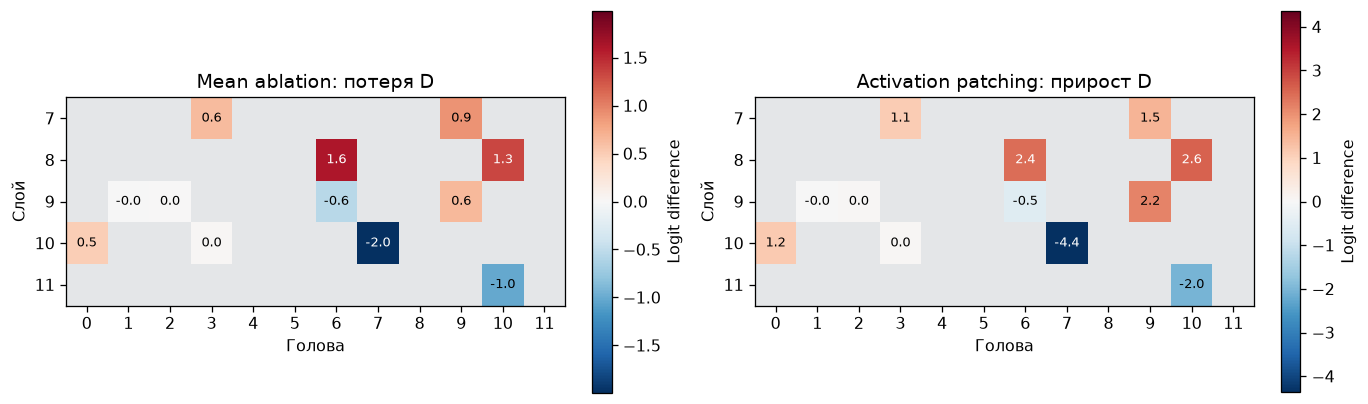

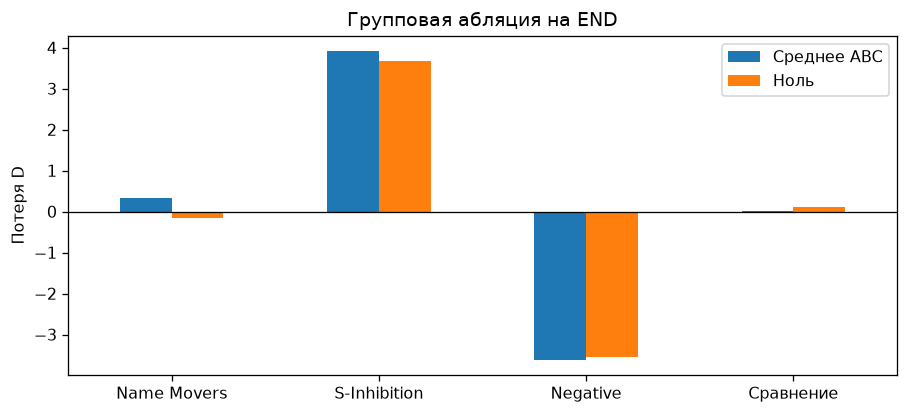

In [ ]:
save_figure(figures.intervention_maps(intervention_rows), "03_intervention_maps")
save_figure(figures.group_ablation(intervention_df), "04_group_ablation")


Каждая цветная клетка — одно вмешательство, усреднённое по 16 фразам; серые головы не проверялись. Слева ухудшаем исходный запуск, справа восстанавливаем испорченный, поэтому шкалы различаются. Подстановка исходных S-Inhibition восстанавливает 98.9% разрыва. Удаление Negative Heads повышает D, что согласуется с их отрицательным вкладом. Средняя и нулевая абляции дают разные эффекты: способ замены имеет значение.


In [ ]:
identity_activation = ioi.intervene(model, small, ioi.S_INHIBITION, clean_z, kind="clean")
activation_error = float((identity_activation["D"] - clean["D"]).abs().max())
assert activation_error < 1e-4


## 5. Path patching

Activation patching меняет все последующие пути от узла. **Path patching** проверяет выбранный путь, например **S-Inhibition → Q Name Movers**. Используем четыре прямых прохода из [приложения B](https://arxiv.org/html/2211.00593v1#A2):

1. Запускаем исходный и ABC-тексты, сохраняя активации: два прохода.
2. В исходном запуске заменяем выход отправителя ABC-активацией, а выходы остальных голов фиксируем. MLP и LayerNorm пересчитываем; сохраняем изменённый вход получателя.
3. Переносим только этот вход в новый исходный запуск и пересчитываем продолжение.

В примере переносим изменённый query Name Movers: так измеряется влияние S-Inhibition именно через этот запрос. Получателем также может быть K, V или последний residual stream перед логитами. Q/K управляют выбором источника, V несёт читаемое содержимое.

Отправитель влияет через MLP и residual stream; промежуточные головы исключены. В коде подменяется **z** — взвешенная сумма V перед матрицей O.

$$\Delta D=\overline D_{clean}-\overline D_{patched}.$$

Положительное значение означает потерю предпочтения IO после подмены пути. Для всех основных опытов заменяем три имени различными ABC-именами. Контроль меняет только S2: эффект на **Previous → K Induction** должен быть нулевым, поскольку S1+1 находится раньше. Результат характеризует это вмешательство, но не доказывает единственность механизма.

In [ ]:
path_cache = paths.prepare_path_cache(model, small, paths.matched_abc_tokens(model, small, keep_prefix=False))
nm_queries = [(l, h, "q", "end") for l, h in ioi.NAME_MOVERS]
si_values = [(l, h, "v", "s2") for l, h in ioi.S_INHIBITION]
late_cases = [(f"L{l}H{h} → выход", [(l, h, "end")], "resid")
              for l, h in ioi.NAME_MOVERS + ioi.NEGATIVE + [(9, 1)]]
late_cases.append(("Name Movers вместе → выход", [(l,h,"end") for l,h in ioi.NAME_MOVERS], "resid"))
internal_cases = [(f"L{l}H{h} → Q Name Movers", [(l, h, "end")], nm_queries)
                  for l, h in ioi.S_INHIBITION]
internal_cases += [
    ("S-Inhibition вместе → Q Name Movers", [(l,h,"end") for l,h in ioi.S_INHIBITION], nm_queries),
    ("Duplicate 0.1, 3.0 → V S-Inhibition", [(0,1,"s2"),(3,0,"s2")], si_values),
    ("Induction 5.5, 6.9 → V S-Inhibition", [(5,5,"s2"),(6,9,"s2")], si_values)]


In [ ]:
path_rows, path_details, path_runs = [], [], {}
for block, cases in [("late", late_cases), ("internal", internal_cases)]:
    for label, senders, receivers in cases:
        run = paths.run_path(model, small, path_cache, senders, receivers)
        assert run["target_only_error"] == 0
        path_runs[label] = run
        path_rows.append({"Путь": label, "block": block, "Потеря D": float((clean["D"] - run["D"]).mean()),
                          "D после": float(run["D"].mean()), "donor": "three names replaced"})
        path_details.extend({"path": label, "example": i, "D": float(d)} for i, d in enumerate(run["D"]))


In [ ]:
previous = paths.run_path(model, small, path_cache, [(2,2,"s1+1"),(4,11,"s1+1")],
                          [(5,5,"k","s1+1"),(6,9,"k","s1+1")])
assert previous["target_only_error"] == 0
path_rows.append({"Путь": "Previous → K Induction", "block": "internal",
                  "Потеря D": float((clean["D"] - previous["D"]).mean()),
                  "D после": float(previous["D"].mean()), "donor": "three names replaced"})
path_details.extend({"path": "Previous → K Induction", "example": i, "D": float(d)}
                    for i, d in enumerate(previous["D"]))
path_df = pd.DataFrame(path_rows)
path_df.to_csv(OUTPUT / "path_patching.csv", index=False)
pd.DataFrame(path_details).to_csv(OUTPUT / "path_patching_per_example.csv", index=False)


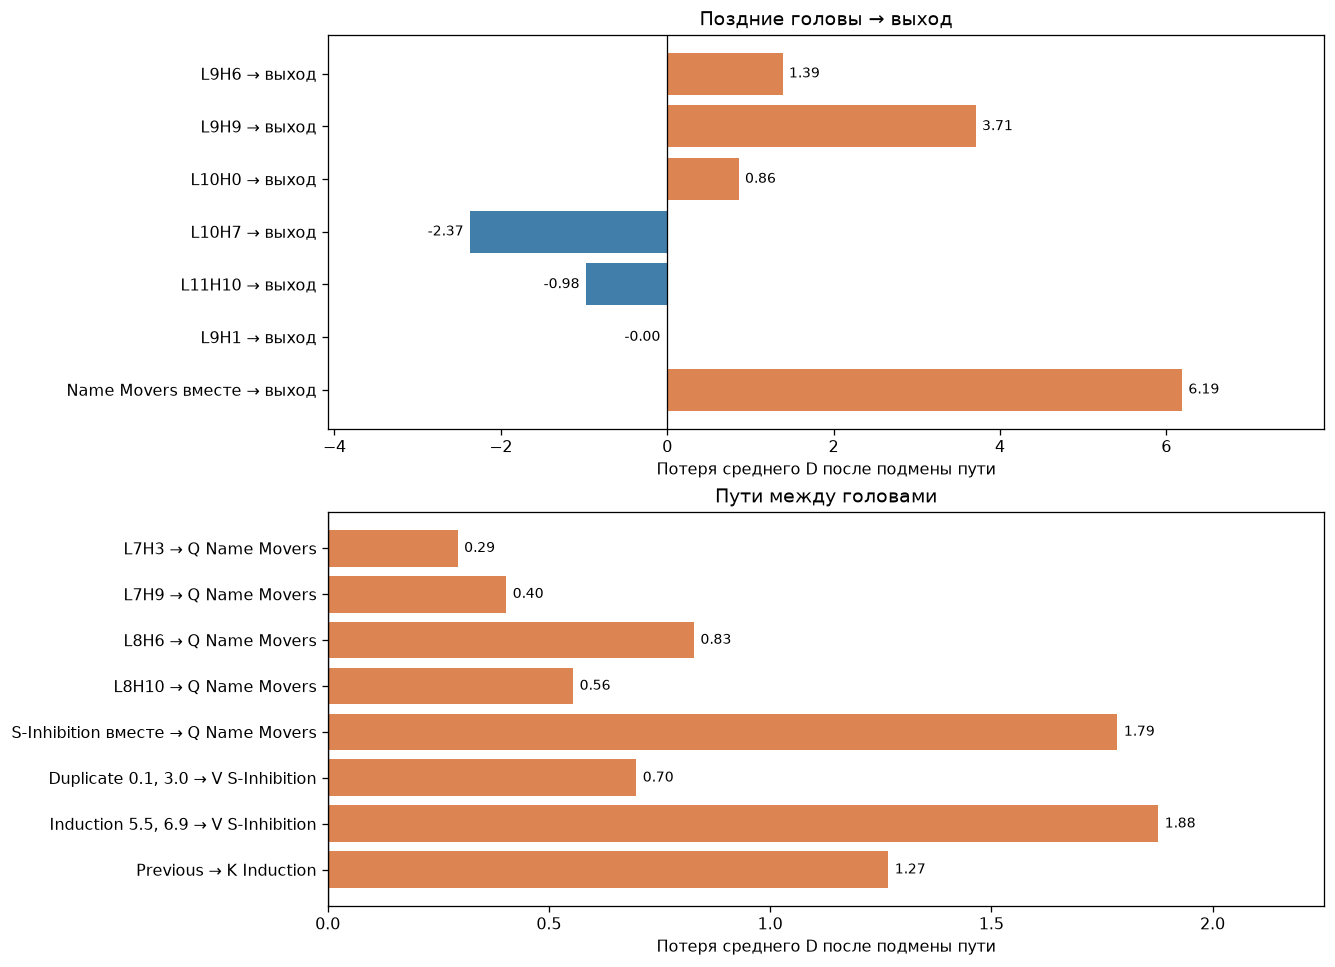

In [ ]:
save_figure(figures.paths(path_df), "05_path_patching")


Name Movers дают положительный вклад через путь к выходу, Negative Heads — отрицательный. Нижняя панель показывает влияние ранних голов через S-Inhibition и влияние S-Inhibition через запросы Name Movers. Групповые эффекты не обязаны равняться сумме отдельных: вычисления нелинейны.


### Как сигнал S-Inhibition меняет выбор источника?

Повторяем уже проверенный путь **S-Inhibition → Q Name Movers** и сохраняем веса внимания. Меняется только переданный запрос Q; входной текст остаётся исходным. Сравниваем, сколько внимания на END получают IO и первое упоминание отправителя S1.


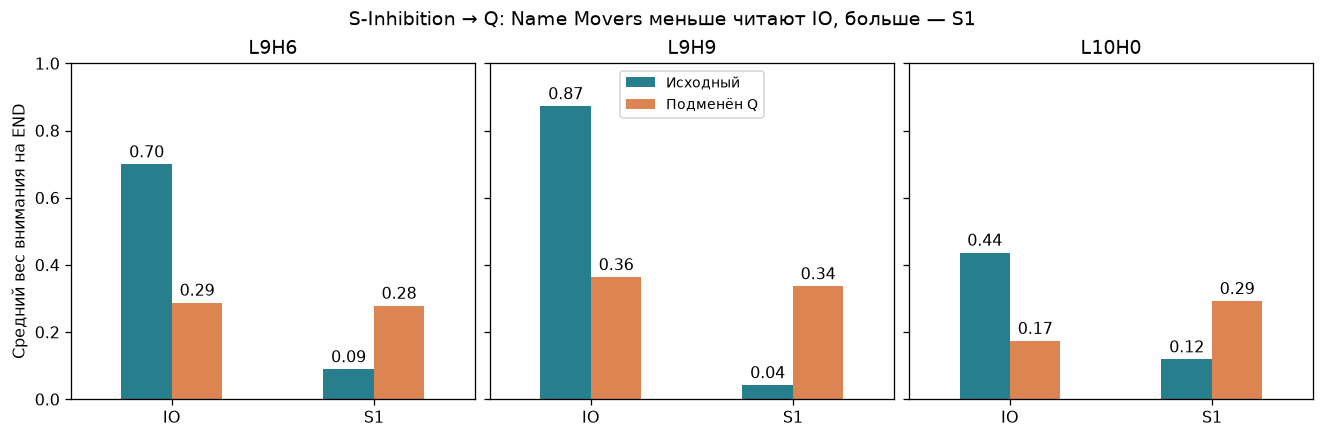

Среднее D: 4.48 → 2.69


In [ ]:
query_run = paths.run_path(
    model, small, path_cache,
    [(l, h, "end") for l, h in ioi.S_INHIBITION], nm_queries,
    capture_attention=True,
)
assert query_run["target_only_error"] == 0
assert torch.allclose(query_run["D"], path_runs["S-Inhibition вместе → Q Name Movers"]["D"], atol=1e-5)
query_rows = []
for layer, head in ioi.NAME_MOVERS:
    for role, position in [("IO", "io_pos"), ("S1", "s1_pos")]:
        for label, pattern in [("Исходный", patterns[layer][:, :, -1, :]),
                               ("Подменён Q", query_run["attention"][layer])]:
            query_rows.append({"head": f"L{layer}H{head}", "role": role, "run": label,
                               "weight": float(pattern[rows, head, small[position]].mean())})
query_df = pd.DataFrame(query_rows)
query_df.to_csv(OUTPUT / "query_attention.csv", index=False)
save_figure(figures.query_attention(query_df), "05b_query_attention")
print(f"Среднее D: {clean['D'].mean():.2f} → {query_run['D'].mean():.2f}")


После подмены Q внимание всех трёх голов к IO падает, к S1 растёт. У L9H9 вес IO меняется с 0.87 до 0.36, S1 — с 0.04 до 0.34; среднее D снижается с 4.48 до 2.69. Так сигнал о повторе влияет на то, какое имя читают Name Movers.


In [ ]:
# Собственное состояние и повторный обычный запуск не должны менять ответ.
replay = paths.frozen_replay(model, small, path_cache)
identity_query = paths.run_path(model, small, path_cache, [(7,3,"end")], nm_queries, identity=True)
identity_resid = paths.run_path(model, small, path_cache, [(9,9,"end")], "resid", identity=True)
future_cache = paths.prepare_path_cache(model, small, paths.matched_abc_tokens(model, small))
future_only = paths.run_path(model, small, future_cache, [(2,2,"s1+1"),(4,11,"s1+1")],
                             [(5,5,"k","s1+1"),(6,9,"k","s1+1")])
path_checks = {"future_only_error": float((future_only["D"] - clean["D"]).abs().max()),
               "frozen_replay": float((replay["D"] - clean["D"]).abs().max()),
               "identity_Q": float((identity_query["D"] - clean["D"]).abs().max()),
               "identity_resid": float((identity_resid["D"] - clean["D"]).abs().max())}
assert max(path_checks.values()) < 1e-4
print("Контроли path patching:", path_checks)


Контроли path patching: {'future_only_error': 0.0, 'frozen_replay': 0.0, 'identity_Q': 0.0, 'identity_resid': 0.0}


Подмена активации самой собой и фиксация всех голов на исходных значениях сохраняют ответ. Изменение только будущего S2 не влияет на ранний путь Previous → K Induction: причинная маска запрещает чтение будущего. Эти контроли проверяют реализацию вмешательств.


### Имя и позиция в сигнале S-Inhibition

Проверяем две составляющие сигнала: **какое имя повторилось** и **где оно встретилось впервые**. Меняем идентичность повторённого имени независимо от позиции первого упоминания. Для исходного `Mary and John ... John` получаем шесть доноров:

| Сигнал имени | Позиция сохранена | Позиция обращена |
|---|---|---|
| Исходный | `Mary John John` | `John Mary John` |
| Посторонние имена | `Alice Bob Bob` | `Bob Alice Bob` |
| Имена поменяны местами | `John Mary Mary` | `Mary John Mary` |

Выходы четырёх S-Inhibition на END переносим из каждого донора в **исходный** текст; последующие вычисления пересчитываем. Это activation patching из [приложения A](https://arxiv.org/html/2211.00593v1#A1), а не изоляция пути. Случайные имена в двух столбцах совпадают, меняется их порядок.

Так различаем эффекты имени и позиции через контрфактические входы, не предполагая, что внутри модели найдены два независимых вектора.

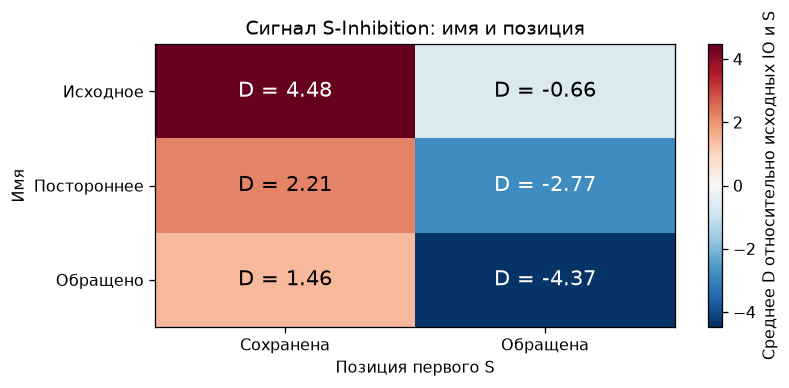

,token_signal,position_signal,donor_example
0,original,original,"When Sarah and Daniel went to the store, Sarah..."
1,original,inverted,"When Daniel and Sarah went to the store, Sarah..."
2,random,original,"When John and Tom went to the store, John gave..."
3,random,inverted,"When Tom and John went to the store, John gave..."
4,inverted,original,"When Daniel and Sarah went to the store, Danie..."
5,inverted,inverted,"When Sarah and Daniel went to the store, Danie..."


In [ ]:
signal_rows, signal_details = signals.evaluate_signals(model, small)
signal_df = pd.DataFrame(signal_rows)
signal_df.to_csv(OUTPUT / "signals.csv", index=False)
pd.DataFrame(signal_details).to_csv(OUTPUT / "signals_per_example.csv", index=False)
grid = signal_df.pivot(index="token_signal", columns="position_signal", values="mean_D").reindex(
    index=["original", "random", "inverted"], columns=["original", "inverted"]).to_numpy()

save_figure(figures.identity_position(grid), "06_identity_position")
display(signal_df[["token_signal", "position_signal", "donor_example"]])


Верхняя левая клетка воспроизводит исходный запуск. При обращении только позиции D меняется с 4.48 до −0.66, только имени — до 1.46, обоих — до −4.37. Значит, сигнал чувствителен и к имени, и к его расположению. Отрицательный D означает предпочтение исходного отправителя при неизменном тексте на входе.


## 6. Обсуждение результатов

Совместно используем три вида свидетельств: внимание показывает выбор источника, copy score характеризует преобразование прочитанного имени, вмешательства измеряют изменение ответа. Их согласованность поддерживает предложенный механизм сильнее, чем одна визуализация внимания.

Сохранение logit difference после выделения circuit оценивает **faithfulness** на нашей выборке. **Completeness** требует проверить, не пропущены ли альтернативные пути; **minimality** — обосновать необходимость каждого включённого узла. Один коэффициент сохранения не заменяет эти проверки. Малые выборки, ограниченное число шаблонов и способ формирования ABC ограничивают обобщение результатов. Наличие MLP в запусках также не позволяет объявить их несущественными.

На двух шаблонах 26 голов сохраняют около 85% среднего эффекта полной модели, но три отдельных ответа меняются. Внимание, диагностика OV и причинные вмешательства согласованно поддерживают основную цепочку статьи: ранние головы передают сведения о повторе, S-Inhibition меняет запросы Name Movers, а те читают и копируют имя получателя. Это воспроизведение механизма на небольшой контролируемой выборке; численные показатели не обязаны совпадать с исходной работой.


In [ ]:
after = ioi.forward_scores(model, small)
cleanup_error = float((after["D"] - clean["D"]).abs().max())
assert cleanup_error < 1e-4
summary = {
    "model": ioi.MODEL, "revision": ioi.REVISION, "device": "cpu",
    "python": sys.executable, "versions": environment, "seed": 42,
    "baseline": baseline_rows, "retention": retention_rows,
    "copy": copy_df.to_dict(orient="records"),
    "group_interventions": [r for r in intervention_rows if r["layer"] is None],
    "paths": path_rows, "signals": signal_rows,
    "query_attention": query_rows, "circuit_failures": failures,
    "controls": {**path_checks, "identity_activation": activation_error, "hook_cleanup": cleanup_error},
    "elapsed_seconds": time.perf_counter() - started,
}
(OUTPUT / "run.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print("Контроли:", summary["controls"])
print("Время вычислений:", round(summary["elapsed_seconds"], 1), "с")
print("Данные и рисунки:", OUTPUT.resolve())


Контроли: {'future_only_error': 0.0, 'frozen_replay': 0.0, 'identity_Q': 0.0, 'identity_resid': 0.0, 'identity_activation': 0.0, 'hook_cleanup': 0.0}
Время вычислений: 91.6 с
Данные и рисунки: /home/nikolay/.codex/visualizations/2026/10/04/01a10928-72fa-7f61-8cdd-be244abbb96b/ioi-study/IOI_research_results


## Источники

1. [Wang et al. Interpretability in the Wild (2022)](https://arxiv.org/abs/2211.00593v1). Основная работа: постановка IOI, 26 голов, абляции и причинные вмешательства; [код авторов](https://github.com/redwoodresearch/Easy-Transformer/blob/main/easy_transformer/ioi_circuit_extraction.py) задаёт состав circuit и позиции.
2. [Vaswani et al. Attention Is All You Need (2017)](https://arxiv.org/abs/1706.03762). Механизм внимания и архитектура Transformer.
3. [Elhage et al. A Mathematical Framework for Transformer Circuits (2021)](https://transformer-circuits.pub/2021/framework/). Residual stream, QK/OV и взаимодействие голов.

Исходный [обзор Indirect Object Identification](https://www.emergentmind.com/topics/indirect-object-identification-ioi) использован как карта темы. В работе подробно воспроизводим его центральный пример — circuit GPT-2 Small из Wang et al.; определения и числа сверяем с первоисточником. Более поздние направления обзора в эксперименты не входят.